In [ ]:
# Reiniciar o programa
#import os
#os.kill(os.getpid(),9)

In [1]:
import boto3
from bs4 import BeautifulSoup, element
import re
import requests
import time
from tqdm import tqdm
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import json
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

In [2]:
df1 =  pd.read_json('data (3).json')
df1

,built_in,location,tipology,amenities,m2,m2_util,timestamp,energetic_efficiency,price,id,house_type
0,{'NULL': True},"{'S': 'Santa Maria e Santo André , Estremoz'}",{'S': 'T1'},{'NULL': True},{'S': '150 m²'},{'S': '150 m²'},{'S': '1712326615.4558148'},{'NULL': True},"{'S': '68,000 €'}",{'S': '32462049'},{'S': 'Detached house'}
1,{'S': '2012'},"{'S': 'São Teotónio , Odemira'}",{'S': 'T3'},{'L': [{'S': 'Swimming pool'}]},{'S': '108 m²'},{'S': '107 m²'},{'S': '1712087970.149109'},{'S': 'a'},"{'S': '550,000 €'}",{'S': '33228432'},{'S': 'flat'}
2,{'S': '2006'},"{'S': 'rua dos Casarões de Maio Nn , Corval, R...",{'S': 'T4'},{'NULL': True},{'S': '156 m²'},{'S': '94 m²'},{'S': '1712170327.760994'},{'S': 'f'},"{'S': '269,000 €'}",{'S': '33280192'},{'S': 'House'}
3,{'S': '2015'},"{'S': 'Urb. Garden, Rosto de Cão (Livramento) ...",{'S': 'T4'},"{'L': [{'S': 'Swimming pool'}, {'S': 'Green ar...",{'S': '195 m²'},{'S': '194 m²'},{'S': '1711647036.675669'},{'NULL': True},"{'S': '850,000 €'}",{'S': '32666708'},{'S': 'flat'}
4,{'S': '1978'},"{'S': 'Santa Maria e Santo André , Estremoz'}",{'S': 'T1'},{'NULL': True},{'S': '39 m²'},{'S': '36 m²'},{'S': '1712326371.6414158'},{'NULL': True},"{'S': '99,800 €'}",{'S': '33093019'},{'S': 'House'}
...,...,...,...,...,...,...,...,...,...,...,...
4484,{'NULL': True},"{'S': 'avenida Catarina Eufémia, 25 , Arcos, E...",{'S': 'T2'},{'NULL': True},{'S': '250 m²'},{'S': '110 m²'},{'S': '1712090353.586932'},{'S': 'd'},"{'S': '37,000 €'}",{'S': '32394670'},{'S': 'flat'}
4485,{'NULL': True},"{'S': 'rua Capitão Formosinho , Vila Alva, Cuba'}",{'S': 'T2'},{'L': [{'S': 'Garden'}]},{'S': '88 m²'},{'S': '75 m²'},{'S': '1712089107.4423838'},{'NULL': True},"{'S': '75,000 €'}",{'S': '32559692'},{'S': 'Detached house'}
4486,{'NULL': True},"{'S': 'Sabóia , Odemira'}",{'S': 'T3'},{'NULL': True},{'S': '211 m²'},{'S': '211 m²'},{'S': '1712085687.6654358'},{'NULL': True},"{'S': '145,000 €'}",{'S': '32884078'},{'S': 'Quinta'}
4487,{'NULL': True},"{'S': 'Vale de Santiago , Odemira'}",{'S': 'T3'},{'L': [{'S': 'Garden'}]},{'S': '242 m²'},{'S': '242 m²'},{'S': '1712088875.99178'},{'S': 'f'},"{'S': '350,000 €'}",{'S': '32816804'},{'S': 'Quinta'}


In [3]:
#boto3.setup_default_session(profile_name='pecd',region_name='eu-west-1')
#dynamodb = boto3.resource('dynamodb')
#client = boto3.client('dynamodb')

def get_db_ids():
    response = client.scan(TableName="houses")
    #print(response["ResponseMetadata"]["HTTPStatusCode"])
    #print(response)
    ids = list(map(lambda x: x["id"]["S"],response["Items"]))
    return response["Items"]

#response = get_db_ids()

#with open('data.json', 'w') as f:
    #json.dump(response, f)


#print(response)
#print(len(response))

#anocon = {}

#print(response[0]["id"]["S"])

#for i in range(len(response)):
    #try:
        #anocon[response[i]["id"]["S"]] = {"ano_construcao" : response[i]['built_in']['S']}
    #except:
        #anocon[response[i]["id"]["S"]] = {"ano_construcao" : response[i]['built_in']['NULL']}

f = open('data (3).json', encoding="utf8")
data = json.load(f)
output = []
for i in range(len(data)):
    output.append(data[i]['price']['S'])

#Processamento dos dados

df = pd.read_json(r'data (3).json')
#print(df.columns)
print(df.columns)

output = df['price']

input = df.drop(columns=['id','price'])
#print(input)

#print(input['amenities'])
amenities = []
for i in range(len(input['amenities'])):
    lista = []
    try:
        for j in range(len(input['amenities'][i]['L'])):
            lista.append(input['amenities'][i]['L'][j]['S'])
    except:
        lista.append(input['amenities'][i]['NULL'])
    amenities.append(lista)

#print(amenities)

for i in range(len(input['amenities'])):
    for j in range(len(input['amenities'][i])):
        if j>0:
            input['amenities'][i] = amenities[i][j]
        else:
            input['amenities'][i] = str(amenities[i][j]) + ' '

#print(input['amenities'])
#print(df['built_in'])

built = []
for i in range(len(input['built_in'])):
    try:
        built.append(input['built_in'][i]['S'])
    except:
        built.append(input['built_in'][i]['NULL'])

input['built_in'] = built

#print(input['location'])
location = []
for i in range(len(input['location'])):
    location.append(input['location'][i]['S'])

input['location'] = location

tipo = []
for i in range(len(input['tipology'])):
    tipo.append(input['tipology'][i]['S'][1:])

input['tipology'] = tipo

mdois = []
for i in range(len(input['m2'])):
    mdois.append(input['m2'][i]['S'][:-2])

input['m2'] = mdois

mdoisu = []
for i in range(len(input['m2_util'])):
    mdoisu.append(input['m2_util'][i]['S'][:-2])

input['m2_util'] = mdoisu

timestamp = []
for i in range(len(input['timestamp'])):
    try:
        timestamp.append(input['timestamp'][i]['S'])
    except:
        timestamp.append(input['timestamp'][i])
input['timestamp'] = timestamp

ene = []
for i in range(len(input['energetic_efficiency'])):
    try:
        ene.append(input['energetic_efficiency'][i]['S'])
    except:
        ene.append(input['energetic_efficiency'][i]['NULL'])


input['energetic_efficiency'] = ene

type = []
for i in range(len(input['house_type'])):
    type.append(input['house_type'][i]['S'])

input['house_type'] = type

Index(['built_in', 'location', 'tipology', 'amenities', 'm2', 'm2_util',
       'timestamp', 'energetic_efficiency', 'price', 'id', 'house_type'],
      dtype='object')


In [4]:
output = pd.DataFrame()
def price_real(data):
    l = []
    for i in range(len(data)):
        dict_values = data['price'][i].values()
        dict_list = list(dict_values) 
        number_str = dict_list[0].split()[0]  
        number_str = number_str.replace(',', '')  
        number_int = int(number_str)
        l.append(number_int)
    #y['Price_Real'] = l
    return l

output['Price_Real'] = price_real(df1)

In [5]:
# Normalizar preço
norm_p = output.loc[:, ['Price_Real']]

def norm_price(y): 
    
    y['Price_Real'] = y['Price_Real'] /y['Price_Real'].abs().max()
    return y
norm_p = norm_price(norm_p)

output['Price_norm'] = norm_p

In [6]:
output

,Price_Real,Price_norm
0,68000,0.004533
1,550000,0.036667
2,269000,0.017933
3,850000,0.056667
4,99800,0.006653
...,...,...
4484,37000,0.002467
4485,75000,0.005000
4486,145000,0.009667
4487,350000,0.023333


In [7]:
output.to_csv('output_d.csv',index=False)

In [8]:
input

,built_in,location,tipology,amenities,m2,m2_util,timestamp,energetic_efficiency,house_type
0,True,"Santa Maria e Santo André , Estremoz",1,True,150,150,1712326615.4558148,True,Detached house
1,2012,"São Teotónio , Odemira",3,Swimming pool,108,107,1712087970.149109,a,flat
2,2006,"rua dos Casarões de Maio Nn , Corval, Reguengo...",4,True,156,94,1712170327.760994,f,House
3,2015,"Urb. Garden, Rosto de Cão (Livramento) , Ponta...",4,Swimming pool,195,194,1711647036.675669,True,flat
4,1978,"Santa Maria e Santo André , Estremoz",1,True,39,36,1712326371.6414158,True,House
...,...,...,...,...,...,...,...,...,...
4484,True,"avenida Catarina Eufémia, 25 , Arcos, Estremoz",2,True,250,110,1712090353.586932,d,flat
4485,True,"rua Capitão Formosinho , Vila Alva, Cuba",2,Garden,88,75,1712089107.4423838,True,Detached house
4486,True,"Sabóia , Odemira",3,True,211,211,1712085687.6654358,True,Quinta
4487,True,"Vale de Santiago , Odemira",3,Garden,242,242,1712088875.99178,f,Quinta


In [9]:
# Aglomerar house_type
"""
'Detached' --> 'Detached', 'Village' <------ 1
'Flat' --> 'Flat', 'Duplex', 'Andar', 'studio'  <------ 2
'House' --> 'House', 'Semi-detached', 'house' <------ 3
'Quinta' --> 'Quinta', 'Country', 'Monte', 'Estate'  <------ 4
'Palace' --> 'Palace', 'Penthouse', 'Manor'   <------ 5
'Mill'  <------ 6
'erraced' :('não há info')  <------ 7
"""
h_t = input.loc[:, ['house_type']]

def substituir_house_type(X):
    X = X.replace('Detached house', 1)
    X = X.replace('Detached', 1)
    X = X.replace('Village house', 1)
    X = X.replace('Village', 1)
    X = X.replace('Flat', 2)
    X = X.replace('flat', 2)
    X = X.replace('Duplex', 2)
    X = X.replace('Andar de moradia', 2)
    X = X.replace('Andar', 2)
    X = X.replace('studio flat', 2)
    X = X.replace('studio', 2)
    X = X.replace('House', 3)
    X = X.replace('Semi-detached house', 3)
    X = X.replace('Semi-detached', 3)
    X = X.replace('house', 3)
    X = X.replace('Quinta', 4)
    X = X.replace('Country house', 4)
    X = X.replace('Country', 4)
    X = X.replace('Monte alentejano', 4)
    X = X.replace('Monte', 4)
    X = X.replace('Estate', 4)
    X = X.replace('Palace', 5)
    X = X.replace('Penthouse', 5)
    X = X.replace('Manor', 5)
    X = X.replace('Mill', 6)
    X = X.replace('erraced house', 7)
    X = X.replace('erraced', 7)
    
    return X
h_t = substituir_house_type(h_t)

# normalizar valores 
def norm_h_t(df1): 
    
    df1['house_type'] = df1['house_type'] /df1['house_type'].abs().max()
    return df1
h_t = norm_h_t(h_t)

input['house_type'] = h_t

# Variação dos dados 

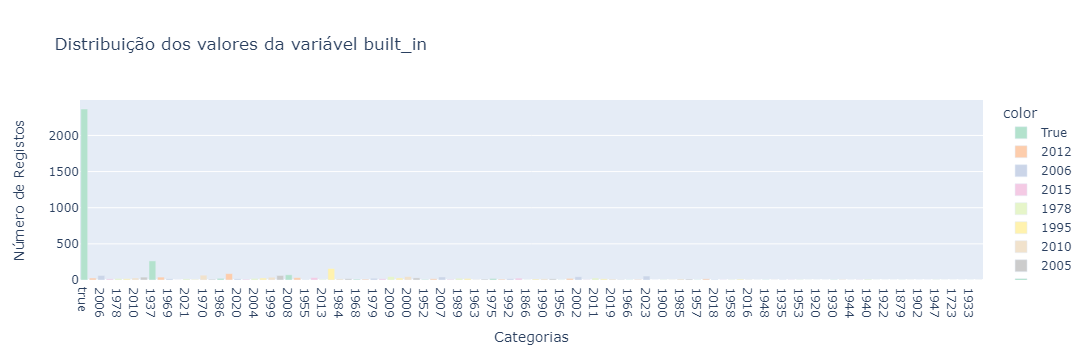

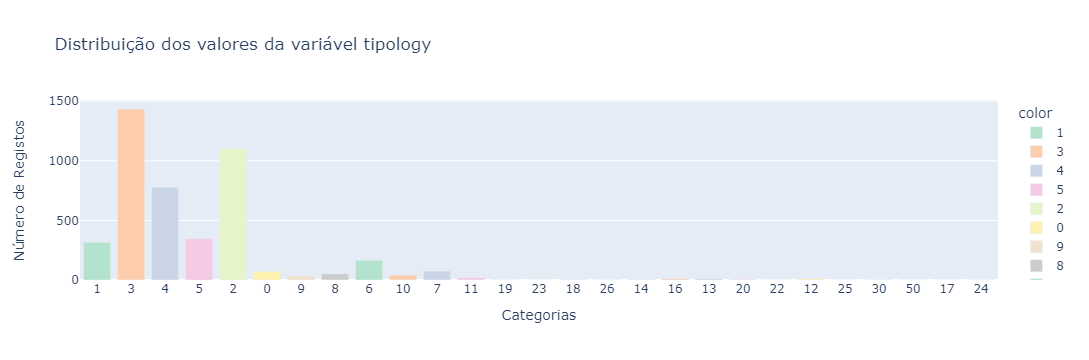

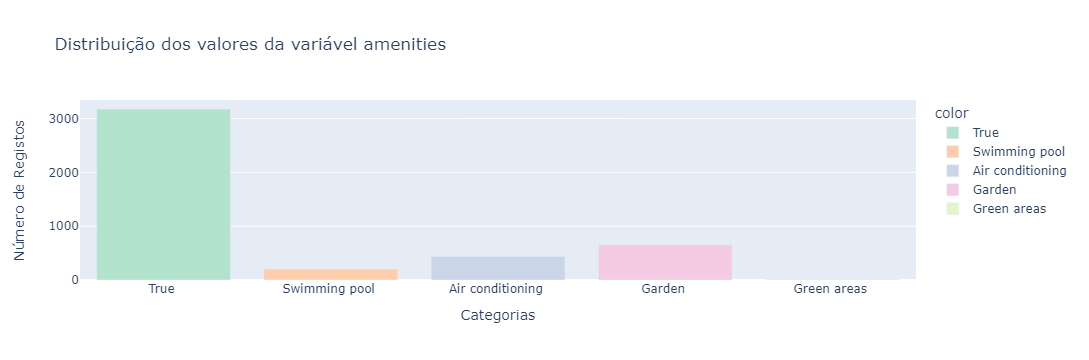

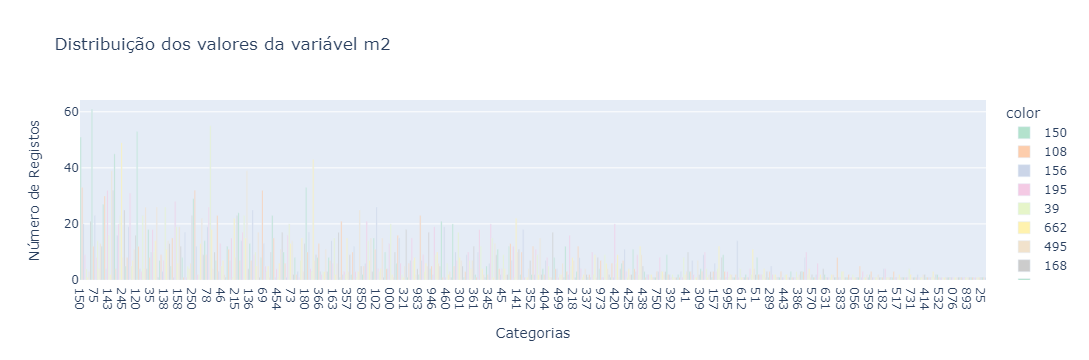

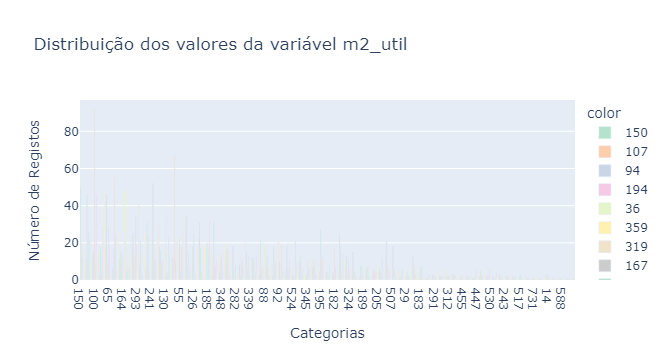

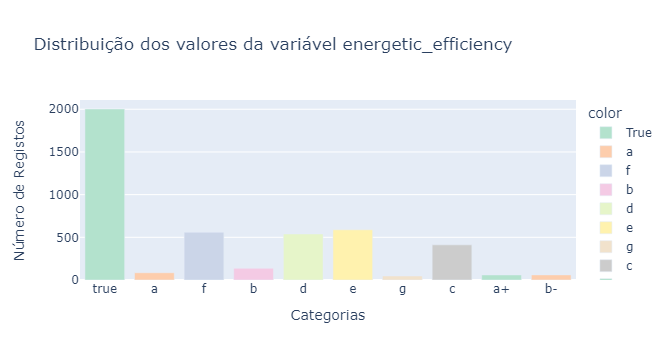

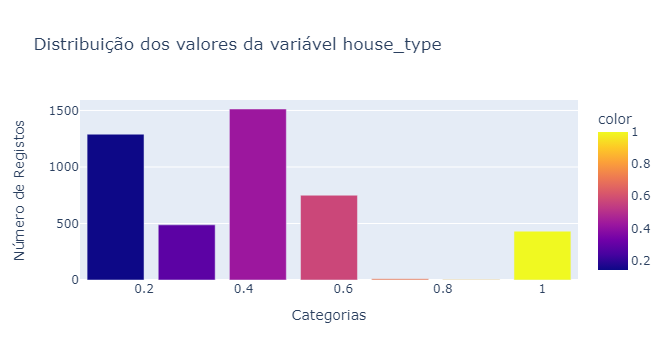

In [10]:
# Variação dos dados 
import plotly.express as px
col = ['built_in','tipology', 'amenities', 'm2', 'm2_util', 'energetic_efficiency', 'house_type']

for nome in col: 
    output = []
    names = input[nome].unique()
    for i in input[nome].unique():
        bt2 = input[nome].value_counts()[i]
        output.append(bt2)
    fig = px.bar(input, x=names, y=output, color = names ,color_discrete_sequence= px.colors.qualitative.Pastel2, title= f'Distribuição dos valores da variável {nome}')
    fig.update_xaxes(title_text='Categorias')
    fig.update_yaxes(title_text='Número de Registos')
    fig.show()

# Tratamento de dados 

## Tipologia 

In [11]:
# Classes 
"""
1 -> 0
2 -> 1
3 -> 2
4 -> 3
5 -> 4
6 -> 5
7 -> 6
8 -> 7
9 -> 8
10 -> 9
11 -> 10 , 11, 12, 13
12 -> 14, 15, 16, 17 
13 -> 18, 19, 20
14 -> 21, .., np.max(input['tipology'])

"""
# Primeiro transforma os valores em nºs inteiros 

l_tipology = []
for i in input['tipology']: 
    l_tipology.append(int(i))
input['tipology'] = l_tipology


# Criar dicionario para as classes
ultimos = list(range(21, np.max(input['tipology'])+1))
dicio_ty = {1: [0], 2: [1], 3: [2], 4: [3], 5: [4], 6: [5], 7: [6], 8: [7], 9: [8], 10: [9], 11: [10, 11, 12, 13], 12: [14, 15, 16, 17], 13: [18, 19, 20], 14: ultimos}

# Objetivo criar uma lista de listas com as pos dos nº das classes estabeecidas 

def agrupar_tipology(X, col, dicio):
    classes = []
    for i in X.index:
        for chave, lista in dicio.items():
            if X[col][i] in lista: 
                classes.append(chave)
    return classes

input['tipology'] = agrupar_tipology(input, 'tipology', dicio_ty)

# Normalizar lista

def norm_tipology(X):
    X['tipology'] = X['tipology'] /X['tipology'].abs().max()
    return X

input = norm_tipology(input)


## m2

In [10]:
# Primeiro transforma os valores em nºs inteiros 

lm2 = []
for i in input['m2']: 
    lm2.append(int(i))
input['m2'] = lm2

# Objetivo agrupar os dados 20 em 20 u.a

def agrupar_m2(X, col):
    saltos = []
    # Nº de classes --> saltos vão ser de 20 em 20 u.a.
    n_c = round(np.max(X[col])/20)
    inicio = 0
    salto = 20
    for ite in range(n_c): 
        l = []
        for i in X.index: 
            if X[col][i] >= inicio and X[col][i] < salto: 
                l.append(i)
        inicio += 20
        salto += 20
        saltos.append(l)
    return saltos
l_m2 = agrupar_m2(input, 'm2')   

# Meter categoria em cada dado

def categoria_m2(X, col, l_m2):
    n_c = round(np.max(X[col])/20)
    classes = list(range(1,n_c + 1))
    for i in range(len(l_m2)): 
        X.loc[l_m2[i], col] = classes[i]
    return X
input = categoria_m2(input, 'm2', l_m2)

# Normalizar os daodos 
def norm_m2(X):
    X['m2'] = X['m2'] /X['m2'].abs().max()
    return X

input = norm_m2(input)

## m2_util

In [11]:
# Primeiro transforma os valores em nºs inteiros 

lm2_u = []
for i in input['m2_util']: 
    lm2_u.append(int(i))
input['m2_util'] = lm2_u

# Objetivo agrupar os dados 20 em 20 u.a
l_m2_u = agrupar_m2(input, 'm2_util')

# Meter categoria em cada dado
input = categoria_m2(input, 'm2_util', l_m2_u)

# Normalizar os dados 
def norm_m2_util(X):
    X['m2_util'] = X['m2_util'] /X['m2_util'].abs().max()
    return X

input = norm_m2_util(input)

In [12]:
input

,built_in,location,tipology,amenities,m2,m2_util,timestamp,energetic_efficiency,house_type
0,True,"Santa Maria e Santo André , Estremoz",0.142857,True,0.16,0.16,1712326615.4558148,True,0.142857
1,2012,"São Teotónio , Odemira",0.285714,Swimming pool,0.12,0.12,1712087970.149109,a,0.285714
2,2006,"rua dos Casarões de Maio Nn , Corval, Reguengo...",0.357143,True,0.16,0.10,1712170327.760994,f,0.428571
3,2015,"Urb. Garden, Rosto de Cão (Livramento) , Ponta...",0.357143,Swimming pool,0.20,0.20,1711647036.675669,True,0.285714
4,1978,"Santa Maria e Santo André , Estremoz",0.142857,True,0.04,0.04,1712326371.6414158,True,0.428571
...,...,...,...,...,...,...,...,...,...
4484,True,"avenida Catarina Eufémia, 25 , Arcos, Estremoz",0.214286,True,0.26,0.12,1712090353.586932,d,0.285714
4485,True,"rua Capitão Formosinho , Vila Alva, Cuba",0.214286,Garden,0.10,0.08,1712089107.4423838,True,0.142857
4486,True,"Sabóia , Odemira",0.285714,True,0.22,0.22,1712085687.6654358,True,0.571429
4487,True,"Vale de Santiago , Odemira",0.285714,Garden,0.26,0.26,1712088875.99178,f,0.571429


# Obter coordenadas

In [13]:
import googlemaps
from datetime import datetime
gmaps = googlemaps.Client(key='{google_maps_api_key}')

# Geocoding an address
lat = []
lng = []

for i in range(len(input['location'])):
    #print(input['location'][i].split(" ")[-1])
    try:
        geocode_result = gmaps.geocode(input['location'][i])
        lat.append(geocode_result[0]['geometry']['location']['lat'])
        lng.append(geocode_result[0]['geometry']['location']['lng'])
    except:
        geocode_result = gmaps.geocode(str(input['location'][i].split(" ")[-1])+" ,Portugal")
        lat.append(geocode_result[0]['geometry']['location']['lat'])
        lng.append(geocode_result[0]['geometry']['location']['lng'])

In [14]:
input['latitude'] = lat
input['longitude'] = lng

In [15]:
loc_lat = input.loc[:, ['latitude']]

# Normalizar os dados 
def norm_latitude(X):
    X['latitude'] = X['latitude'] /X['latitude'].abs().max()
    return X

loc_lat = norm_latitude(loc_lat)
input['latitude_norm'] = loc_lat


loc_lng = input.loc[:, ['longitude']]
# Normalizar os dados 
def norm_longitude(X):
    X['longitude'] = X['longitude'] /X['longitude'].abs().max()
    return X

loc_lng = norm_longitude(loc_lng)
input['longitude_norm'] = loc_lng 

In [16]:
input = input.drop(['location'], axis=1)

In [17]:
input

,built_in,tipology,amenities,m2,m2_util,timestamp,energetic_efficiency,house_type,latitude,longitude,latitude_norm,longitude_norm
0,True,0.142857,True,0.16,0.16,1712326615.4558148,True,0.142857,38.845392,-7.589737,0.692057,-0.070647
1,2012,0.285714,Swimming pool,0.12,0.12,1712087970.149109,a,0.285714,37.508494,-8.704422,0.668239,-0.081023
2,2006,0.357143,True,0.16,0.10,1712170327.760994,f,0.428571,38.449443,-7.479972,0.685003,-0.069626
3,2015,0.357143,Swimming pool,0.20,0.20,1711647036.675669,True,0.285714,37.764840,-25.603582,0.672806,-0.238325
4,1978,0.142857,True,0.04,0.04,1712326371.6414158,True,0.428571,38.845392,-7.589737,0.692057,-0.070647
...,...,...,...,...,...,...,...,...,...,...,...,...
4484,True,0.214286,True,0.26,0.12,1712090353.586932,d,0.285714,38.832497,-7.507994,0.691827,-0.069886
4485,True,0.214286,Garden,0.10,0.08,1712089107.4423838,True,0.142857,38.250758,-7.900406,0.681463,-0.073539
4486,True,0.285714,True,0.22,0.22,1712085687.6654358,True,0.571429,37.477889,-8.550128,0.667694,-0.079587
4487,True,0.285714,Garden,0.26,0.26,1712088875.99178,f,0.571429,37.751592,-8.412954,0.672570,-0.078310


# Download Datasets!!

In [18]:
input.to_csv('input_d.csv', index=False)